In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_excel('Online Retail.xlsx')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
# converting the dataframe to csv format
df = df.to_csv('Online Retail.csv', index=False)


In [ ]:
# Reading the CSV file back into a DataFrame
df = pd.read_csv('Online Retail.csv')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
# Display basic information about the DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [ ]:
# checking the number of duplicate rows
df.duplicated().sum()

np.int64(5268)

In [ ]:
# drop duplicates
df.drop_duplicates(inplace=True)
df.info()

<class 'pandas.DataFrame'>
Index: 536641 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    536641 non-null  str    
 1   StockCode    536641 non-null  str    
 2   Description  535187 non-null  str    
 3   Quantity     536641 non-null  int64  
 4   InvoiceDate  536641 non-null  str    
 5   UnitPrice    536641 non-null  float64
 6   CustomerID   401604 non-null  float64
 7   Country      536641 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 36.8 MB


In [ ]:
# Checking for missing values
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

In [9]:
df.sample(30)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
469404,576593,20619,TROPICAL PASSPORT COVER,1,2011-11-15 14:48:00,2.10,15720.0,United Kingdom
291492,562456,23321,SMALL WHITE HEART OF WICKER,12,2011-08-05 10:39:00,1.65,15194.0,United Kingdom
179458,552277,22035,VINTAGE CARAVAN GREETING CARD,12,2011-05-08 12:34:00,0.42,13642.0,United Kingdom
387182,570269,16048,TEATIME ROUND PENCIL SHARPENER,48,2011-10-10 10:16:00,0.12,17227.0,United Kingdom
462401,575973,21791,VINTAGE HEADS AND TAILS CARD GAME,12,2011-11-13 13:03:00,1.25,NaN,EIRE
95849,544467,85206A,CREAM FELT EASTER EGG BASKET,1,2011-02-20 15:51:00,1.65,14502.0,United Kingdom
481850,577359,22469,HEART OF WICKER SMALL,4,2011-11-18 16:07:00,1.65,14903.0,United Kingdom
360101,568211,22402,MAGNETS PACK OF 4 VINTAGE COLLAGE,12,2011-09-25 15:59:00,0.39,13429.0,United Kingdom
5826,536876,22308,TEA COSY BLUE STRIPE,3,2010-12-03 11:36:00,5.06,NaN,United Kingdom
261569,559876,20974,12 PENCILS SMALL TUBE SKULL,3,2011-07-13 11:09:00,0.65,15752.0,United Kingdom


In [ ]:
# Checking for cancelled invoices and negative quantities
c_invoices = df[df['InvoiceNo'].str.startswith('C', na=False)]
print('total number of cancelled invoices:', len(c_invoices))
print('Max quantity in cancelled invoices:', c_invoices['Quantity'].max())

other_negatives = df[(df['Quantity'] < 0) & (~df['InvoiceNo'].str.startswith('C', na=False))]
print('total number of negative quantity invoices:', len(other_negatives))
print(other_negatives[['InvoiceNo', 'Quantity', 'UnitPrice', 'Description']].head(10))

total number of cancelled invoices: 9251
Max quantity in cancelled invoices: -1
total number of negative quantity invoices: 1336
     InvoiceNo  Quantity  UnitPrice Description
2406    536589       -10        0.0         NaN
4347    536764       -38        0.0         NaN
7188    536996       -20        0.0         NaN
7189    536997       -20        0.0         NaN
7190    536998        -6        0.0         NaN
7192    537000       -22        0.0         NaN
7193    537001        -6        0.0         NaN
7195    537003        -2        0.0         NaN
7196    537004       -30        0.0         NaN
7197    537005       -70        0.0         NaN


In [ ]:
# Remove rows with zero or negative unit prices
zero_prices = df[df['UnitPrice'] <= 0]
print('creepy prices:', len(zero_prices))

print(c_invoices[['InvoiceNo', 'Description', 'Quantity', 'UnitPrice', 'CustomerID']].head())

creepy prices: 2512
    InvoiceNo                       Description  Quantity  UnitPrice  \
141   C536379                          Discount        -1      27.50   
154   C536383   SET OF 3 COLOURED  FLYING DUCKS        -1       4.65   
235   C536391    PLASTERS IN TIN CIRCUS PARADE        -12       1.65   
236   C536391  PACK OF 12 PINK PAISLEY TISSUES        -24       0.29   
237   C536391  PACK OF 12 BLUE PAISLEY TISSUES        -24       0.29   

     CustomerID  
141     14527.0  
154     15311.0  
235     17548.0  
236     17548.0  
237     17548.0  


In [12]:
# فحص عينة من المرتجعات الرسمية (c_invoices)
print(other_negatives[['InvoiceNo', 'Description', 'Quantity', 'UnitPrice', 'CustomerID']].head(10))

     InvoiceNo Description  Quantity  UnitPrice  CustomerID
2406    536589         NaN       -10        0.0         NaN
4347    536764         NaN       -38        0.0         NaN
7188    536996         NaN       -20        0.0         NaN
7189    536997         NaN       -20        0.0         NaN
7190    536998         NaN        -6        0.0         NaN
7192    537000         NaN       -22        0.0         NaN
7193    537001         NaN        -6        0.0         NaN
7195    537003         NaN        -2        0.0         NaN
7196    537004         NaN       -30        0.0         NaN
7197    537005         NaN       -70        0.0         NaN


In [ ]:
# Remove rows with negative quantities that are not cancelled invoices
df.drop(other_negatives.index, inplace=True)
df.info()

<class 'pandas.DataFrame'>
Index: 535305 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    535305 non-null  str    
 1   StockCode    535305 non-null  str    
 2   Description  534713 non-null  str    
 3   Quantity     535305 non-null  int64  
 4   InvoiceDate  535305 non-null  str    
 5   UnitPrice    535305 non-null  float64
 6   CustomerID   401604 non-null  float64
 7   Country      535305 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 36.8 MB


In [14]:
print(zero_prices[['InvoiceNo', 'Description', 'Quantity', 'UnitPrice', 'CustomerID']].head(10))

     InvoiceNo Description  Quantity  UnitPrice  CustomerID
622     536414         NaN        56        0.0         NaN
1970    536545         NaN         1        0.0         NaN
1971    536546         NaN         1        0.0         NaN
1972    536547         NaN         1        0.0         NaN
1987    536549         NaN         1        0.0         NaN
1988    536550         NaN         1        0.0         NaN
2024    536552         NaN         1        0.0         NaN
2025    536553         NaN         3        0.0         NaN
2026    536554         NaN        23        0.0         NaN
2406    536589         NaN       -10        0.0         NaN


In [ ]:
# Remove rows with zero or negative unit prices
df = df[df['UnitPrice'] > 0]
print('total rows after removing zero and negative prices:', len(df))

total rows after removing zero and negative prices: 534129


In [17]:
df.info()
print('total Nans: ', df.isnull().sum().sum())

<class 'pandas.DataFrame'>
Index: 534129 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    534129 non-null  str    
 1   StockCode    534129 non-null  str    
 2   Description  534129 non-null  str    
 3   Quantity     534129 non-null  int64  
 4   InvoiceDate  534129 non-null  str    
 5   UnitPrice    534129 non-null  float64
 6   CustomerID   401564 non-null  float64
 7   Country      534129 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 36.7 MB
total Nans:  132565


In [ ]:
# Identify and handle missing CustomerID values
df['Is_Guest'] = df['CustomerID'].isnull()

df['CustomerID'] = df['CustomerID'].fillna('Guest_' + df['InvoiceNo'].astype(str))

df.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Is_Guest       0
dtype: int64

In [ ]:
# 20 random samples
df.sample(20)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Is_Guest
71380,542121,85066,CREAM SWEETHEART MINI CHEST,2,2011-01-25 14:33:00,12.75,17515.0,United Kingdom,False
23127,538179,22810,SET OF 6 T-LIGHTS SNOWMEN,6,2010-12-10 09:52:00,2.95,17696.0,United Kingdom,False
62736,541516,21381,MINI WOODEN HAPPY BIRTHDAY GARLAND,2,2011-01-18 17:34:00,3.29,Guest_541516,United Kingdom,True
365810,568716,21739,COSY SLIPPER SHOES SMALL GREEN,1,2011-09-28 16:13:00,2.46,Guest_568716,United Kingdom,True
112215,545874,22993,SET OF 4 PANTRY JELLY MOULDS,3,2011-03-07 15:02:00,1.25,12841.0,United Kingdom,False
420904,572913,22550,HOLIDAY FUN LUDO,3,2011-10-26 16:21:00,3.75,15993.0,United Kingdom,False
390261,570505,22720,SET OF 3 CAKE TINS PANTRY DESIGN,3,2011-10-11 09:41:00,4.95,14841.0,United Kingdom,False
483801,577507,21591,COSY HOUR CIGAR BOX MATCHES,2,2011-11-20 12:42:00,1.25,14710.0,United Kingdom,False
109274,545591,22411,JUMBO SHOPPER VINTAGE RED PAISLEY,10,2011-03-04 10:28:00,1.95,17581.0,United Kingdom,False
449775,575138,23534,WALL ART STOP FOR TEA,1,2011-11-08 15:24:00,12.46,Guest_575138,United Kingdom,True


In [ ]:
# Cleaning and formatting the data for analysis
df['CustomerID'] = df['CustomerID'].astype(str).str.replace(r'\.0$', '', regex=True)
df['Description'] = df['Description'].astype(str).str.strip().upper()
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Is_Guest
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False


In [25]:
df['Description'] = df['Description'].str.upper()
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Is_Guest
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False


In [ ]:
# Generating new columns for analysis
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
df['Is_Cancelled'] = df['InvoiceNo'].str.startswith('C', na=False)
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Is_Guest,TotalPrice,Is_Cancelled
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,False,15.30,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,20.34,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,False,22.00,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,20.34,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,20.34,False


In [ ]:
# Save the cleaned DataFrame to a new CSV file
df.to_csv('Online Retail Cleaned.csv', index=False)
print('saved successfully, total rows:', len(df))

saved successfully, total rows: 534129


In [29]:
# 1. إعادة قراءة الملف المحفوظ للتأكد من سلامة التصدير
test_df = pd.read_csv('Online Retail Cleaned.csv')

# 2. فحص الهيكل والخلو من الفراغات
print("--- تقرير فحص ملف الـ CSV المحفوظ ---")
print(f"Shape: {test_df.shape[0]:,} rows × {test_df.shape[1]} cols")
print(f"Total Null Values: {test_df.isnull().sum().sum()}")
print(f"Null values in InvoiceNo: {test_df['InvoiceNo'].isnull().sum()}")
print(f"Num of unique InvoiceNo: {test_df['InvoiceNo'].nunique():,}")
print(f"Total Revenue: £{test_df['TotalPrice'].sum():,.2f}")
print(f"Total Refunds: £{test_df[test_df['Is_Cancelled']]['TotalPrice'].sum():,.2f}")

--- تقرير فحص ملف الـ CSV المحفوظ ---
Shape: 534,129 rows × 11 cols
Total Null Values: 0
Null values in InvoiceNo: 0
Num of unique InvoiceNo: 23,796
Total Revenue: £9,748,131.07
Total Refunds: £-893,979.73


Matplotlib is building the font cache; this may take a moment.


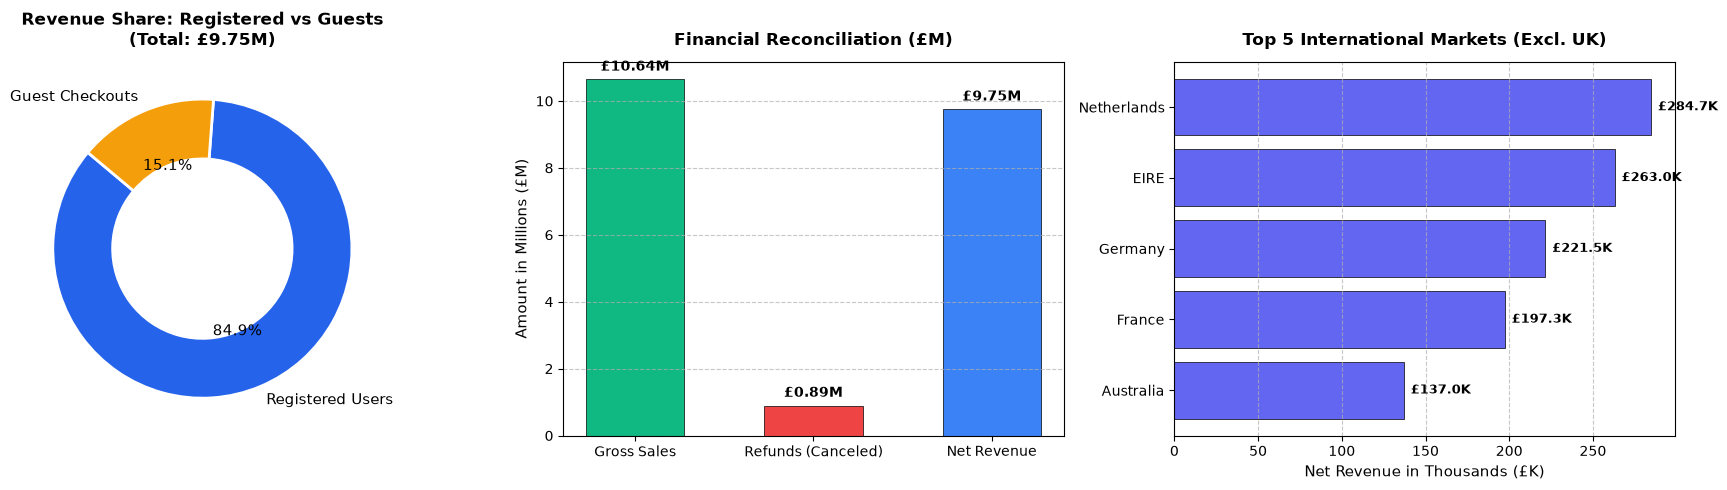

تم حفظ الرسوم البيانية بنجاح باسم: eda_visualizations.png


In [ ]:
# Generate Visualizations for EDA
import matplotlib.pyplot as plt
import seaborn as sns

# 1. إعداد مساحة الرسم (3 رسوم متجاورة)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- الرسم الأول: حصة مبيعات الزوار مقابل العملاء المسجلين (Donut Chart) ---
guest_rev = test_df.groupby('Is_Guest')['TotalPrice'].sum()
axes[0].pie(
    [guest_rev[False], guest_rev[True]], 
    labels=['Registered Users', 'Guest Checkouts'], 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=['#2563EB', '#F59E0B'], 
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2),
    textprops={'fontsize': 11}
)
axes[0].set_title('Revenue Share: Registered vs Guests\n(Total: £9.75M)', fontsize=12, fontweight='bold', pad=12)

# --- الرسم الثاني: التسوية المالية (إجمالي المبيعات مقابل المرتجعات وصافي الإيراد) ---
gross_sales = test_df[~test_df['Is_Cancelled']]['TotalPrice'].sum() / 1e6
refunds = abs(test_df[test_df['Is_Cancelled']]['TotalPrice'].sum()) / 1e6
net_rev = test_df['TotalPrice'].sum() / 1e6

metrics = ['Gross Sales', 'Refunds (Canceled)', 'Net Revenue']
values = [gross_sales, refunds, net_rev]
colors_bar = ['#10B981', '#EF4444', '#3B82F6']

bars = axes[1].bar(metrics, values, color=colors_bar, width=0.55, edgecolor='black', linewidth=0.5)
axes[1].set_ylabel('Amount in Millions (£M)', fontsize=11)
axes[1].set_title('Financial Reconciliation (£M)', fontsize=12, fontweight='bold', pad=12)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    height = bar.get_height()
    axes[1].annotate(f'£{height:.2f}M',
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 4), textcoords="offset points",
                     ha='center', va='bottom', fontsize=10, fontweight='bold')

# --- الرسم الثالث: أعلى 5 أسواق دولية بعد السوق المحلي البريطاني ---
top_countries = test_df[test_df['Country'] != 'United Kingdom'].groupby('Country')['TotalPrice'].sum().nlargest(5)
bars3 = axes[2].barh(top_countries.index[::-1], (top_countries.values / 1e3)[::-1], color='#6366F1', edgecolor='black', linewidth=0.5)
axes[2].set_xlabel('Net Revenue in Thousands (£K)', fontsize=11)
axes[2].set_title('Top 5 International Markets (Excl. UK)', fontsize=12, fontweight='bold', pad=12)
axes[2].grid(axis='x', linestyle='--', alpha=0.7)

for bar in bars3:
    width = bar.get_width()
    axes[2].annotate(f'£{width:.1f}K',
                     xy=(width, bar.get_y() + bar.get_height() / 2),
                     xytext=(5, 0), textcoords="offset points",
                     ha='left', va='center', fontsize=9, fontweight='bold')

# ضبط المحاذاة وحفظ الصورة
plt.tight_layout()
plt.savefig('eda_visualizations.png', dpi=300, bbox_inches='tight')
plt.show()
print("تم حفظ الرسوم البيانية بنجاح باسم: eda_visualizations.png")

In [ ]:
#Inverting the InvoiceDate column to datetime format for further analysis
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')
print('InvoiceDate dtype:', df['InvoiceDate'].dtype)

InvoiceDate dtype: datetime64[us]
